# Interior Point 2: Quadratic Programs

**Seong Cho** · ACME Volume 2, Lab 17

**Lab objective:** implement a primal-dual Interior Point method for convex quadratic constrained optimization and explore applications in elastic membrane theory and finance.

<sub>Lab specification from the *Volume 2* lab manual of [Foundations of Applied Mathematics](https://foundations-of-applied-mathematics.github.io/) (BYU ACME), © Dr. J. Humpherys, used under [CC BY 3.0 US](http://creativecommons.org/licenses/by/3.0/us/). Problem statements are quoted from the spec; the notes are condensed from it. Solutions are my own.</sub>

> **Note.** This notebook requires [CVXOPT](http://cvxopt.org/) (`pip install cvxopt`), used in Problem 4 and for the checks. It was run with cvxopt 1.3.3.

The solution code uses `np.row_stack()`, which NumPy 2.0 deprecated as an alias of `np.vstack()`. The code is kept as written, and the setup cell hides that one `DeprecationWarning`.

In [1]:
import warnings
import numpy as np
from scipy import linalg as la
from scipy.sparse import spdiags
from scipy.optimize import minimize
from matplotlib import pyplot as plt
from mpl_toolkits.mplot3d import axes3d
import cvxopt as opt

warnings.filterwarnings("ignore", message="`row_stack` alias is deprecated", category=DeprecationWarning)
opt.solvers.options['show_progress'] = False

# Tight tolerances for CVXOPT when it serves as the reference solution in the checks.
tight = {'show_progress': False, 'abstol': 1e-12, 'reltol': 1e-12, 'feastol': 1e-12}

## Quadratic Optimization Problems

Interior point methods originated as an alternative to the Simplex method for linear optimization, but they can be adapted to convex optimization problems in general. A quadratic constrained optimization problem differs from a linear one only in that the objective function is quadratic:

$$\begin{aligned} \text{minimize} \quad & \frac{1}{2}\mathbf{x}^TQ\mathbf{x} + \mathbf{c}^T\mathbf{x} \\ \text{subject to} \quad & A\mathbf{x} \succeq \mathbf{b}, \\ & G\mathbf{x} = \mathbf{h}. \end{aligned}$$

The lab restricts attention to positive semidefinite quadratic terms (indefinite quadratic objectives generally admit many local minima, complicating matters considerably). Such problems are called *convex*. To simplify the exposition, only inequality constraints are allowed (generalizing to equality constraints is not difficult):

$$\begin{aligned} \text{minimize} \quad & \frac{1}{2}\mathbf{x}^TQ\mathbf{x} + \mathbf{c}^T\mathbf{x} \\ \text{subject to} \quad & A\mathbf{x} \succeq \mathbf{b}, \end{aligned}$$

where $Q$ is an $n \times n$ positive semidefinite matrix, $\mathbf{x}, \mathbf{c} \in \mathbb{R}^n$, $A$ is $m \times n$, and $\mathbf{b} \in \mathbb{R}^m$. The Lagrangian is

$$\mathcal{L}(\mathbf{x}, \boldsymbol{\mu}) = \frac{1}{2}\mathbf{x}^TQ\mathbf{x} + \mathbf{c}^T\mathbf{x} - \boldsymbol{\mu}^T(A\mathbf{x} - \mathbf{b}), \tag{17.1}$$

where $\boldsymbol{\mu} \in \mathbb{R}^m$ is the (as of yet unknown) Lagrange multiplier. A nonnegative slack vector $\mathbf{y} \in \mathbb{R}^m$ turns the inequality $A\mathbf{x} - \mathbf{b} \succeq \mathbf{0}$ into the equality

$$A\mathbf{x} - \mathbf{b} - \mathbf{y} = \mathbf{0} \implies \mathbf{y} = A\mathbf{x} - \mathbf{b}. \tag{17.2}$$

Equations 17.1 and 17.2, together with complementary slackness, give the KKT conditions:

$$\begin{aligned} Q\mathbf{x} - A^T\boldsymbol{\mu} + \mathbf{c} &= \mathbf{0}, \\ A\mathbf{x} - \mathbf{y} - \mathbf{b} &= \mathbf{0}, \\ y_i\mu_i &= 0, \quad i = 1, 2, \ldots, m, \\ \mathbf{y}, \boldsymbol{\mu} &\succeq \mathbf{0}. \end{aligned}$$

## Quadratic Interior Point Method

The method adapts the linear programming one. With $Y = \operatorname{diag}(y_1, \ldots, y_m)$, $M = \operatorname{diag}(\mu_1, \ldots, \mu_m)$, and $\mathbf{e} \in \mathbb{R}^m$ a vector of all ones, the roots of

$$F(\mathbf{x}, \mathbf{y}, \boldsymbol{\mu}) = \begin{bmatrix} Q\mathbf{x} - A^T\boldsymbol{\mu} + \mathbf{c} \\ A\mathbf{x} - \mathbf{y} - \mathbf{b} \\ YM\mathbf{e} \end{bmatrix} = \mathbf{0}, \qquad (\mathbf{y}, \boldsymbol{\mu}) \succeq \mathbf{0}$$

satisfy the KKT conditions. Its derivative matrix is

$$DF(\mathbf{x}, \mathbf{y}, \boldsymbol{\mu}) = \begin{bmatrix} Q & 0 & -A^T \\ A & -I & 0 \\ 0 & M & Y \end{bmatrix},$$

and the duality measure is

$$\nu = \frac{\mathbf{y}^T\boldsymbol{\mu}}{m}.$$

### Search Direction

As in the linear case, the search direction solves

$$DF(\mathbf{x}, \mathbf{y}, \boldsymbol{\mu}) \begin{bmatrix} \Delta\mathbf{x} \\ \Delta\mathbf{y} \\ \Delta\boldsymbol{\mu} \end{bmatrix} = -F(\mathbf{x}, \mathbf{y}, \boldsymbol{\mu}) + \begin{bmatrix} \mathbf{0} \\ \mathbf{0} \\ \sigma\nu\mathbf{e} \end{bmatrix}, \tag{17.3}$$

where $\sigma \in [0, 1)$ is the centering parameter.

## Problem 1: The quadratic interior point solver

> **Problem 1.** Copy your `interiorPoint()` function from the previous lab into your solutions file for this lab, renaming it `qInteriorPoint()`. This new function should accept the arrays $Q$, $\mathbf{c}$, $A$, and $\mathbf{b}$, a tuple of arrays `guess` giving initial estimates for $\mathbf{x}$, $\mathbf{y}$, and $\boldsymbol{\mu}$ (this will be explained later), along with the keyword arguments `niter=20` and `tol=1e-16`.
>
> Modify your code to match the $F$ and $DF$ described above, and calculate the search direction $(\Delta\mathbf{x}^T, \Delta\mathbf{y}^T, \Delta\boldsymbol{\mu}^T)$ by solving Equation 17.3. Use $\sigma = \frac{1}{10}$ for the centering parameter.
>
> Hint: What are the dimensions of $F$ and $DF$?

My complete function, which also contains the step length and iteration of Problem 2 (described below). $F$ has $n + 2m$ entries and $DF$ is $(n+2m) \times (n+2m)$. One fix was needed in `stepSize()`: if no entry of $\Delta\boldsymbol{\mu}$ (or $\Delta\mathbf{y}$) is negative, the masked array is empty and `np.min()` raised a `ValueError`; `initial=1` now gives the spec's $\beta_{\max} = 1$ (or $\delta_{\max} = 1$) in that case. Without the fix, 3 of the 200 random problems in the check under Problem 2 stopped with that error.

In [2]:
# Problems 1-2
def qInteriorPoint(Q, c, A, b, guess, niter=20, tol=1e-16, verbose=False):
    """Solve the Quadratic program min .5 x^T Q x +  c^T x, Ax >= b
    using an Interior Point method.

    Parameters:
        Q ((n,n) ndarray): Positive semidefinite objective matrix.
        c ((n, ) ndarray): linear objective vector.
        A ((m,n) ndarray): Inequality constraint matrix.
        b ((m, ) ndarray): Inequality constraint vector.
        guess (3-tuple of arrays of lengths n, m, and m): Initial guesses for
            the solution x and lagrange multipliers y and eta, respectively.
        niter (int > 0): The maximum number of iterations to execute.
        tol (float > 0): The convergence tolerance.

    Returns:
        x ((n, ) ndarray): The optimal point.
        val (float): The minimum value of the objective function.
    """
    m = len(b)
    n = len(c)
    # Define the function that returns matrix F
    def KKT_F(x, y, mu):
        F_r1 = Q@x - A.T@mu + c
        F_r2 = A@x - y - b
        F_r3 = y*mu
        return np.concatenate([F_r1,F_r2,F_r3])
    # Save the first and second block rows of DF since they don't change
    DF_r1 = np.column_stack([Q, np.zeros((n,m)), -A.T])
    DF_r2 = np.column_stack([A, -np.eye(m), np.zeros((m,m))])
    # Define the function that returns the search direction
    def searchDirection(x, y, mu, s=0.1):
        F = KKT_F(x, y, mu)
        DF_r3 = np.column_stack([np.zeros((m,n)), np.diag(mu), np.diag(y)])
        DF = np.row_stack([DF_r1, DF_r2, DF_r3])
        nu = np.dot(y,mu)/m
        p = np.concatenate([np.zeros(m+n), s*nu*np.ones(m)])
        return la.lu_solve(la.lu_factor(DF), -F + p)
    # Defind the function that returns the stepsize, along with the delta vector
    def stepSize(x, y, mu):
        direction = searchDirection(x, y, mu)
        d_x = direction[:n]
        d_y = direction[n:n+m]
        d_mu = direction[n+m:]
        # Fixed: initial=1 makes the max step 1 when no entry of d_mu (or d_y) is
        # negative, as the spec says; np.min of the empty array raised a ValueError.
        beta = np.min([1, np.min((-mu/d_mu)[d_mu<0], initial=1)])
        delta = np.min([1, np.min((-y/d_y)[d_y<0], initial=1)])
        return np.min([0.95*beta, 0.95*delta]), d_x, d_y, d_mu
    # Use the predefined function startingPoint to get the initial point
    x, y, mu = startingPoint(Q, c, A, b, guess)
    # Repeat the following for niter times
    for i in range(niter):
        alpha, d_x, d_y, d_mu = stepSize(x, y, mu)
        # Update each of the variables
        x += alpha*d_x
        y += alpha*d_y
        mu += alpha*d_mu
        nu = np.dot(y,mu) / m
        # Stopping criteria
        if abs(nu) < tol:
            return x, (1/2)*np.dot(x,Q@x) + np.dot(c,x)
    return x, (1/2)*np.dot(x,Q@x) + np.dot(c,x)

## Step Length

Step nearly as far as possible without violating the nonnegativity constraints, but back off slightly from the maximum, because an overly greedy step at one iteration may prevent a decent step at the next. The step size is

$$\alpha = \max\{a \in (0, 1] \mid \tau(\mathbf{y}, \boldsymbol{\mu}) + a(\Delta\mathbf{y}, \Delta\boldsymbol{\mu}) \succeq \mathbf{0}\},$$

where $\tau \in (0, 1)$ controls how much we back off; for now $\tau = 0.95$. (In general $\tau$ can be made to approach 1 at each successive iteration, which may speed up convergence.) This is equivalent to the previous lab's method, except that a single step length is used for all three parameters:

$$\beta_{\max} = \min\{1, \min\{-\mu_i/\Delta\mu_i \mid \Delta\mu_i < 0\}\}, \qquad \delta_{\max} = \min\{1, \min\{-y_i/\Delta y_i \mid \Delta y_i < 0\}\},$$

since $\boldsymbol{\mu}, \mathbf{y} \ge 0$. If all of the entries of $\Delta\boldsymbol{\mu}$ are positive, let $\beta_{\max} = 1$, and likewise for $\delta_{\max}$. Then back off:

$$\beta = \min(1, \tau\beta_{\max}), \qquad \delta = \min(1, \tau\delta_{\max}), \qquad \alpha = \min(\beta, \delta).$$

The next point is $(\mathbf{x}_{k+1}, \mathbf{y}_{k+1}, \boldsymbol{\mu}_{k+1}) = (\mathbf{x}_k, \mathbf{y}_k, \boldsymbol{\mu}_k) + \alpha(\Delta\mathbf{x}_k, \Delta\mathbf{y}_k, \Delta\boldsymbol{\mu}_k)$, which completes one iteration.

## Initial Point

The starting point $(\mathbf{x}_0, \mathbf{y}_0, \boldsymbol{\mu}_0)$ has an important effect on convergence. The spec provides this function to compute an appropriate one:

In [3]:
def startingPoint(G, c, A, b, guess):
    """
    Obtain an appropriate initial point for solving the QP
    .5 x^T Gx + x^T c s.t. Ax >= b.
    Parameters:
        G -- symmetric positive semidefinite matrix shape (n,n)
        c -- array of length n
        A -- constraint matrix shape (m,n)
        b -- array of length m
        guess -- a tuple of arrays (x, y, mu) of lengths n, m, and m, resp.
    Returns:
        a tuple of arrays (x0, y0, l0) of lengths n, m, and m, resp.
    """
    m,n = A.shape
    x0, y0, l0 = guess

    # Initialize linear system
    N = np.zeros((n+m+m, n+m+m))
    N[:n,:n] = G
    N[:n, n+m:] = -A.T
    N[n:n+m, :n] = A
    N[n:n+m, n:n+m] = -np.eye(m)
    N[n+m:, n:n+m] = np.diag(l0)
    N[n+m:, n+m:] = np.diag(y0)
    rhs = np.empty(n+m+m)
    rhs[:n] = -(G.dot(x0) - A.T.dot(l0)+c)
    rhs[n:n+m] = -(A.dot(x0) - y0 - b)
    rhs[n+m:] = -(y0*l0)

    sol = la.solve(N, rhs)
    dx = sol[:n]
    dy = sol[n:n+m]
    dl = sol[n+m:]

    y0 = np.maximum(1, np.abs(y0 + dy))
    l0 = np.maximum(1, np.abs(l0+dl))

    return x0, y0, l0

A tuple of arrays `guess` is still needed: provide a reasonable guess for $\mathbf{x}$, and set $\mathbf{y}$ and $\boldsymbol{\mu}$ to arrays of ones. The whole algorithm:

```text
1: procedure Interior Point Method for QP
2:     Choose initial point (x0, y0, µ0).
3:     while k < niters and ν < tol: do
4:         Calculate the duality measure ν.
5:         Solve 17.3 for the search direction (∆xk, ∆yk, ∆µk).
6:         Calculate the step length α.
7:         (xk+1, yk+1, µk+1) = (xk, yk, µk) + α(∆xk, ∆yk, ∆µk).
```

(The loop is meant to continue while $\nu$ is at least `tol`.)

## Problem 2: Completing and testing the solver

> **Problem 2.** Complete the implementation of `qInteriorPoint()`. Return the optimal point $\mathbf{x}$ as well as the final objective function value. You may want to print out the duality measure $\nu$ to check the progress of the iteration.
>
> Test your algorithm on the simple problem
>
> $$\begin{aligned} \text{minimize} \quad & \frac{1}{2}x_1^2 + x_2^2 - x_1x_2 - 2x_1 - 6x_2 \\ \text{subject to} \quad & -x_1 - x_2 \ge -2, \\ & x_1 - 2x_2 \ge -2, \\ & -2x_1 - x_2 \ge -3, \\ & x_1, x_2 \ge 0. \end{aligned}$$
>
> In this case, we have for the objective function matrix $Q$ and vector $\mathbf{c}$,
>
> $$Q = \begin{bmatrix} 1 & -1 \\ -1 & 2 \end{bmatrix}, \qquad \mathbf{c} = \begin{bmatrix} -2 \\ -6 \end{bmatrix}.$$
>
> The constraint matrix $A$ and vector $\mathbf{b}$ are given by:
>
> $$A = \begin{bmatrix} -1 & -1 \\ 1 & -2 \\ -2 & -1 \\ 1 & 0 \\ 0 & 1 \end{bmatrix}, \qquad \mathbf{b} = \begin{bmatrix} -2 \\ -2 \\ -3 \\ 0 \\ 0 \end{bmatrix}.$$
>
> Use $\mathbf{x} = [.5, .5]$ as the initial guess. The correct minimizer is $\left[\frac{2}{3}, \frac{4}{3}\right]$.

The iteration is in `qInteriorPoint()` above. My file's test passed `guess` as `np.array([[0.5, 0.5], np.ones(5), np.ones(5)])`; NumPy 1.24 and later refuse to build an array from rows of different lengths (a `ValueError`), so the test here passes the tuple of arrays that the spec asks for. The reference is `cvxopt.solvers.qp()`, which minimizes $\frac{1}{2}\mathbf{x}^TP\mathbf{x} + \mathbf{q}^T\mathbf{x}$ subject to $G\mathbf{x} \preceq \mathbf{h}$, so it gets $G = -A$ and $\mathbf{h} = -\mathbf{b}$.

In [4]:
Q = np.array([[1,-1],[-1,2]])
c = np.array([-2,-6])
A = np.array([[-1,-1],[1,-2],[-2,-1],[1,0],[0,1]])
b = np.array([-2,-2,-3,0,0])
guess = (np.array([0.5, 0.5]), np.ones(5), np.ones(5))
x, val = qInteriorPoint(Q, c, A, b, guess)
print("x =", x, "  value =", val)

ref = opt.solvers.qp(opt.matrix(Q, tc='d'), opt.matrix(c, tc='d'), opt.matrix(-A, tc='d'), opt.matrix(-b, tc='d'), options=tight)
print("cvxopt: x =", np.ravel(ref['x']), "  value =", ref['primal objective'])
assert np.allclose(x, [2/3, 4/3]) and np.isclose(val, ref['primal objective'])

x = [0.66666667 1.33333333]   value = -8.222222222222221
cvxopt: x = [0.66666667 1.33333333]   value = -8.222222222220445


A larger check against `cvxopt.solvers.qp()` on 200 random strictly convex QPs ($Q = MM^T + 0.1I$) with up to 9 variables and up to 3 times as many inequality constraints, each built to be feasible around a random point that also serves as the initial guess.

In [5]:
rng = np.random.default_rng(17)
for trial in range(200):
    n = rng.integers(2, 10)
    m = rng.integers(n, 3*n)
    M = rng.standard_normal((n, n))
    Q = M @ M.T + 0.1*np.eye(n)
    c = rng.standard_normal(n)
    A = rng.standard_normal((m, n))
    x0 = rng.standard_normal(n)
    b = A @ x0 - rng.random(m)                  # x0 is strictly feasible.
    x, val = qInteriorPoint(Q, c, A, b, (x0.copy(), np.ones(m), np.ones(m)))
    ref = opt.solvers.qp(opt.matrix(Q), opt.matrix(c), opt.matrix(-A), opt.matrix(-b), options=tight)
    assert np.allclose(x, np.ravel(ref['x']), atol=1e-7) and np.isclose(val, ref['primal objective'])
print("All 200 random QPs agree with cvxopt.")

All 200 random QPs agree with cvxopt.


> **Note.** The Interior Point methods presented in this and the preceding labs are only special cases of the more general Interior Point algorithm. The general version can be used to solve many convex optimization problems, provided that one can derive the corresponding KKT conditions and duality measure $\nu$.

## Application: Optimal Elastic Membranes

The properties of elastic membranes (stretchy materials like a thin rubber sheet) are of interest in certain fields of mathematics and various sciences: a mathematical model can be used by biologists to study interfaces in cellular regions in an organism, or by engineers to design tensile structures. Configurations of elastic membranes can often be described as solutions to an optimization problem. As a simple example, we find the shape of a large circus tent with the Interior Point method.

Model the tent, held up by a few poles, as a square two-dimensional grid where each grid point has the height of the tent at that point. At a grid point containing a tent pole, the tent height is at least the height of the pole; at all other grid points, it is at least zero (ground height). Flattening the grid gives a one-dimensional vector $\mathbf{x}$ of tent heights, and with $L$ the flattened tent pole structure (mainly zeros, except where there is a pole), the constraints are

$$\mathbf{x} \succeq L.$$

The theory of elastic membranes claims that such materials tend to naturally minimize a quantity known as the *Dirichlet energy*. On the discrete grid this energy has the form $\frac{1}{2}\mathbf{x}^TH\mathbf{x} + \mathbf{c}^T\mathbf{x}$, where $H$ is a particular positive semidefinite matrix closely related to Laplace's Equation, $\mathbf{c}$ is a vector whose entries are all equal to $-(n-1)^{-2}$, and $n$ is the side length of the grid. So the circus tent solves

$$\begin{aligned} \text{minimize} \quad & \frac{1}{2}\mathbf{x}^TH\mathbf{x} + \mathbf{c}^T\mathbf{x} \\ \text{subject to} \quad & \mathbf{x} \succeq L. \end{aligned}$$

(The spec's Figure 17.1 shows a tent pole configuration and the corresponding tent.) The spec provides the function for the Dirichlet energy matrix $H$:

In [6]:
def laplacian(n):
    """Construct the discrete Dirichlet energy matrix H for an n x n grid."""
    data = -1*np.ones((5, n**2))
    data[2,:] = 4
    data[1, n-1::n] = 0
    data[3, ::n] = 0
    diags = np.array([-n, -1, 0, 1, n])
    return spdiags(data, diags, n**2, n**2).toarray()

The spec's tent pole configuration for a grid of side length $n$, its initial guesses, and its solve-and-plot code:

```python
# Create the tent pole configuration.
>>> L = np.zeros((n,n))
>>> L[n//2-1:n//2+1,n//2-1:n//2+1] = .5
>>> m = [n//6-1, n//6, int(5*(n/6.))-1, int(5*(n/6.))]
>>> mask1, mask2 = np.meshgrid(m, m)
>>> L[mask1, mask2] = .3
>>> L = L.ravel()

# Set initial guesses.
>>> x = np.ones((n,n)).ravel()
>>> y = np.ones(n**2)
>>> mu = np.ones(n**2)

>>> from matplotlib import pyplot as plt
>>> from mpl_toolkits.mplot3d import axes3d

# Calculate the solution.
>>> z = qInteriorPoint(H, c, A, L, (x,y,mu))[0].reshape((n,n))

# Plot the solution.
>>> domain = np.arange(n)
>>> X, Y = np.meshgrid(domain, domain)
>>> fig = plt.figure()
>>> ax1 = fig.add_subplot(111, projection='3d')
>>> ax1.plot_surface(X, Y, z, rstride=1, cstride=1, color='r')
>>> plt.show()
```

The vector $\mathbf{c}$, the constraint matrix $A$, and $H$ (from `laplacian()`) are left to the student.

## Problem 3: The circus tent

> **Problem 3.** Solve the circus tent problem with the tent pole configuration given above, for grid side length $n = 15$. Plot your solution.

The constraint $\mathbf{x} \succeq L$ is $A\mathbf{x} \succeq \mathbf{b}$ with $A = I$ and $\mathbf{b} = L$.

In [7]:
# Problem 3
def circus(n=15):
    """Solve the circus tent problem for grid size length 'n'.
    Display the resulting figure.
    """
    # Initialize L
    L = np.zeros((n,n))
    L[n//2-1:n//2+1,n//2-1:n//2+1] = 0.5
    m = [n//6-1, n//6, int(5*(n/6.))-1, int(5*(n/6.))]
    mask1, mask2 = np.meshgrid(m,m)
    L[mask1, mask2] = .3
    L = L.ravel()
    # Initialize H, c, A
    H = laplacian(n)
    c = -(n-1)**(-2) * np.ones(n**2)
    A = np.eye(n**2)
    # Initial guesses
    x = np.ones((n,n)).ravel()
    y = np.ones(n**2)
    mu = np.ones(n**2)
    # Solve, then plot the function
    z = qInteriorPoint(H, c, A, L, (x,y,mu))[0].reshape((n,n))
    domain = np.arange(n)
    X, Y = np.meshgrid(domain, domain)
    fig = plt.figure()
    ax1 = fig.add_subplot(111, projection='3d')
    ax1.plot_surface(X, Y, z, rstride=1, cstride=1, color='r')
    plt.show()

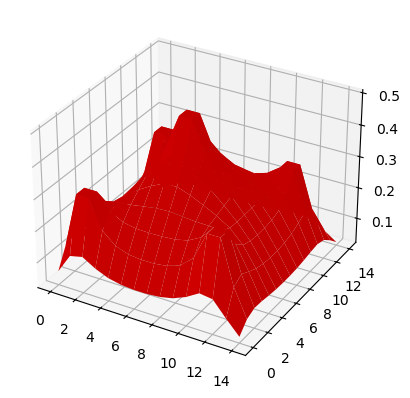

In [8]:
circus()

`circus()` only plots, so the check solves the same problem (rebuilt from the spec's setup) with `qInteriorPoint()` and with `cvxopt.solvers.qp()`, using $G = -I$ and $\mathbf{h} = -L$, and confirms the tent stays on or above the poles and the ground.

In [9]:
n = 15
L = np.zeros((n,n))
L[n//2-1:n//2+1, n//2-1:n//2+1] = .5
idx = [n//6-1, n//6, int(5*(n/6.))-1, int(5*(n/6.))]
mask1, mask2 = np.meshgrid(idx, idx)
L[mask1, mask2] = .3
L = L.ravel()
H = laplacian(n)
c = -(n-1)**(-2) * np.ones(n**2)

z, val = qInteriorPoint(H, c, np.eye(n**2), L, (np.ones(n**2), np.ones(n**2), np.ones(n**2)))
ref = opt.solvers.qp(opt.matrix(H), opt.matrix(c), opt.matrix(-np.eye(n**2)), opt.matrix(-L), options=tight)
print("max |z - cvxopt| =", np.abs(z - np.ravel(ref['x'])).max())
print("energy:", val, " cvxopt:", ref['primal objective'])
print("min(z - L) =", (z - L).min())
assert np.allclose(z, np.ravel(ref['x']), atol=1e-6) and np.all(z >= L - 1e-9)

max |z - cvxopt| = 1.0283440765590512e-13
energy: 0.5444829399471781  cvxopt: 0.5444829399471456
min(z - L) = 8.715250743307479e-15


## Application: Markowitz Portfolio Optimization

Suppose you have money saved up with no intention of consuming it soon. Hidden in your living quarters or on your person, it loses value over time due to inflation, not to mention the risk of burglary or accidental loss. A bank account is safer and may add interest. Government bonds or company stocks come with their own sets of risks and returns. How can you invest so as to maximize the return (the wealth gained over the investment) while still exercising caution and avoiding excessive risk? Economist and Nobel laureate Harry Markowitz developed the mathematical underpinnings of and answer to this question in his work on *modern portfolio theory*.

A *portfolio* is a set of investments over a period of time; each investment is a financial asset (such as a stock or bond) together with the proportion of wealth allocated to it. An asset is a random variable, a sequence of values over time: the variance of these values is associated with its *risk*, and the percent change over each time period is related to its *return*. Here every asset has positive risk (there are no riskless assets).

The portfolio consists of $n$ risky assets and an allocation vector $\mathbf{x} = (x_1, \ldots, x_n)^T$, where $x_i$ is the proportion of wealth invested in asset $i$, so $\sum_{i=1}^n x_i = 1$. If asset $i$ has expected rate of return $\mu_i$ and standard deviation $\sigma_i$, the total return on the portfolio is $\sum_{i=1}^n \mu_i x_i$, and its risk is $\sqrt{\mathbf{x}^TQ\mathbf{x}}$, where $Q$ is the covariance matrix of the $n$ assets (always positive semidefinite; it captures the variances and correlations of the assets).

For a prescribed return $R$ there are in general many allocations; it is wise to choose the one minimizing the risk:

$$\begin{aligned} \text{minimize} \quad & \frac{1}{2}\mathbf{x}^TQ\mathbf{x} \\ \text{subject to} \quad & \sum_{i=1}^n x_i = 1 \\ & \sum_{i=1}^n \mu_i x_i = R. \end{aligned}$$

(Minimizing $\frac{1}{2}\mathbf{x}^TQ\mathbf{x}$ is equivalent to minimizing $\sqrt{\mathbf{x}^TQ\mathbf{x}}$.) Since $\mathbf{x}$ is not constrained to be nonnegative, the solution may have negative entries, which indicates *short selling* those assets. To disallow short selling, add the constraint $\mathbf{x} \succeq \mathbf{0}$.

Each return $R$ paired with its minimal risk $\sigma$ gives a point on the risk-return plane, and these points form a hyperbola. The risk-return pair of any portfolio, optimal or not, lies in the region bounded on the left by the hyperbola. Its positively-sloped portion is the *efficient frontier*, since those points are optimal portfolios; portfolios to the right of it are *inefficient*, since we could either increase the return while keeping the risk constant, or decrease the risk while keeping the return constant (the spec's Figure 17.2).

The risk and return of each asset are in general unknown (no one can predict the stock market with complete certainty), so they are estimated from past data. With $k$ previous return values $\mathbf{y}^i = [y^i_1, \ldots, y^i_k]^T$ for asset $i$, estimate its expected rate of return by the average of $y^i_1, \ldots, y^i_k$, its variance by the variance of the data, and the covariance matrix of all the assets by the covariance matrix of the vectors $\mathbf{y}^1, \ldots, \mathbf{y}^n$.

## Problem 4: Portfolio optimization

> **Problem 4.** The text file `portfolio.txt` contains historical stock data for several assets (U.S. bonds, gold, S&P 500, etc). In particular, the first column gives the years corresponding to the data, and the remaining eight columns give the historical returns of eight assets over the course of these years. Use this data to estimate the covariance matrix $Q$ as well as the expected rates of return $\mu_i$ for each asset. Assuming that we want to guarantee an expected return of $R = 1.13$ for our portfolio, find the optimal portfolio both with and without short selling.
>
> Since the problem contains both equality and inequality constraints, use the QP solver in CVXOPT rather than your `qInteriorPoint()` function.
>
> Hint: Use `numpy.cov()` to compute $Q$.

In [10]:
# Problem 4
def portfolio(filename="portfolio.txt"):
    """Markowitz Portfolio Optimization

    Parameters:
        filename (str): The name of the portfolio data file.

    Returns:
        (ndarray) The optimal portfolio with short selling.
        (ndarray) The optimal portfolio without short selling.
    """
    n = 8
    R = 1.13
    # Load data
    data = np.loadtxt(filename)
    # Estimate Q and mu
    Q = opt.matrix(np.cov(data.T[1:]))
    p = opt.matrix(np.zeros(n))
    mu = np.mean(data[:,1:], axis=0)
    # Define the contraints
    G = opt.matrix(np.eye(n))
    h = opt.matrix(np.zeros(n))
    A = opt.matrix(np.stack([np.ones(n), mu]))
    b = opt.matrix(np.array([1, R]))
    # With shortselling
    sol1 = opt.solvers.qp(Q, p, A=A, b=b)
    # Without shortselling
    sol2 = opt.solvers.qp(Q, p, -G, h, A, b)

    return np.ravel(sol1['x']), np.ravel(sol2['x'])

The two portfolios, with their returns and risks. Independent checks: with short selling the problem has only equality constraints, so its solution also comes from the KKT linear system $\begin{bmatrix} Q & B^T \\ B & 0 \end{bmatrix}\begin{bmatrix} \mathbf{x} \\ \boldsymbol{\lambda} \end{bmatrix} = \begin{bmatrix} \mathbf{0} \\ (1, R)^T \end{bmatrix}$, where the rows of $B$ are $\mathbf{1}^T$ and $\boldsymbol{\mu}^T$; without short selling, `scipy.optimize.minimize()` (SLSQP) solves the bounded problem. `portfolio()` runs CVXOPT at its default tolerances, which leave the weights accurate to about $10^{-4}$ (the third asset shows 0.0001 where the exact weight is 0), so that comparison uses a looser tolerance and also compares the objective values.

In [11]:
x_short, x_noshort = portfolio()

data = np.loadtxt('portfolio.txt')
Qp = np.cov(data.T[1:])
mu = data[:,1:].mean(axis=0)
R, n = 1.13, 8
np.set_printoptions(precision=4, suppress=True)
for name, xp in [("with short selling", x_short), ("without short selling", x_noshort)]:
    print(f"{name:22}: {xp}")
    print(f"{'':22}  sum = {xp.sum():.6f}, return = {mu @ xp:.6f}, risk = {np.sqrt(xp @ Qp @ xp):.6f}")
np.set_printoptions(precision=8, suppress=False)

B = np.vstack([np.ones(n), mu])
K = np.block([[Qp, B.T], [B, np.zeros((2, 2))]])
x_kkt = np.linalg.solve(K, np.r_[np.zeros(n), 1, R])[:n]
cons = [{'type': 'eq', 'fun': lambda x: x.sum() - 1}, {'type': 'eq', 'fun': lambda x: mu @ x - R}]
res = minimize(lambda x: .5*x @ Qp @ x, np.ones(n)/n, jac=lambda x: Qp @ x, method='SLSQP',
               bounds=[(0, None)]*n, constraints=cons, options={'ftol': 1e-14, 'maxiter': 500})
assert np.allclose(x_short, x_kkt, atol=1e-6)
assert res.success and np.allclose(x_noshort, res.x, atol=2e-4) and np.all(x_noshort >= -1e-8)
assert np.isclose(x_noshort @ Qp @ x_noshort, res.x @ Qp @ res.x, rtol=1e-6)
print("Both portfolios match the independent solutions.")

with short selling    : [-1.342  -1.5488 -1.4544  1.6392 -0.39    3.6057  0.2828  0.2075]
                        sum = 1.000000, return = 1.130000, risk = 0.089085
without short selling : [0.     0.     0.0001 0.388  0.     0.0293 0.3421 0.2405]
                        sum = 1.000000, return = 1.130000, risk = 0.139504
Both portfolios match the independent solutions.


The efficient frontier for this data, traced by solving the same two problems with `cvxopt.solvers.qp()` over a range of returns $R$ (without short selling, $R$ can only range between the smallest and largest $\mu_i$). The two optimal portfolios above are marked.

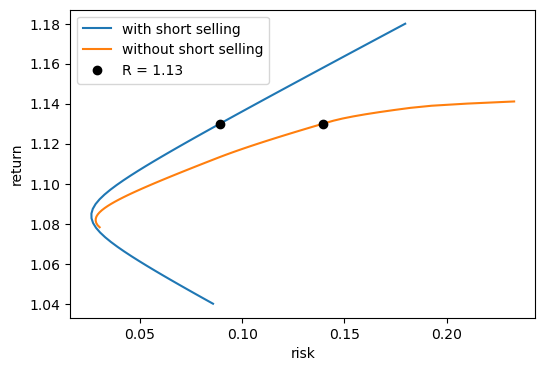

In [12]:
def min_risk(R, short=True):
    A = opt.matrix(np.vstack([np.ones(n), mu]))
    b = opt.matrix([1., R])
    if short:
        sol = opt.solvers.qp(opt.matrix(Qp), opt.matrix(np.zeros(n)), A=A, b=b)
    else:
        sol = opt.solvers.qp(opt.matrix(Qp), opt.matrix(np.zeros(n)), opt.matrix(-np.eye(n)), opt.matrix(np.zeros(n)), A, b)
    x = np.ravel(sol['x'])
    return np.sqrt(x @ Qp @ x)

R_short = np.linspace(1.04, 1.18, 60)
R_long = np.linspace(mu.min() + 1e-4, mu.max() - 1e-4, 60)
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot([min_risk(r) for r in R_short], R_short, label="with short selling")
ax.plot([min_risk(r, short=False) for r in R_long], R_long, label="without short selling")
ax.plot(np.sqrt(x_short @ Qp @ x_short), 1.13, 'ko')
ax.plot(np.sqrt(x_noshort @ Qp @ x_noshort), 1.13, 'ko', label="R = 1.13")
ax.set_xlabel("risk"); ax.set_ylabel("return"); ax.legend()
plt.show()